Paquetes necesarios

In [1]:
import cv2  
import numpy as np
import matplotlib.pyplot as plt
import csv
from scipy.optimize import least_squares

### Resolución de la Tarea 1: Detección de monedas en tiempo real

TAREA: Los ejemplos ilustrativos anteriores permiten saber el número de monedas presentes en la imagen ideal proporcionada. ¿Cómo determinar la cantidad de dinero presente en ella? A partir únicamente de las dimensiones, una sugerencia impicaríaj en primer término identificar de forma interactiva (por ejemplo haciendo clic en la imagen) una moneda de un valor fijo en la imagen (por ejemplo de 1€) para permitir establecer una relación entre píxeles y mo¡ilímetros. Tras obtener esa información y las dimensiones en milímetros de las distintas monedas, es factible calcular la cantidad de dinero en la imagen ideal.

Una vez resuelto el reto con la imagen ideal proporcionada, diseña un demostrador en vivo que a partir de la entrada de vídeo de la cámara, determine el dinero presente en la escena. Si bien 
no hay restricciones sobre utilizar medidas geométricas o de color, o cualquier clasificador, no deben hacer uso de modelos de aprendizaje profundo. ¿Funciona correctamente? ¿Se observan problemas?
Posibles extras serían la presencia de objetos que no son monedas y/o haya solape entre las monedas.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

Nota: Para establecer la correspondencia entre píxeles y milímetros, comentar que la moneda de un euro tiene un diámetro de 23.25 mm. la de 50 céntimos de 24.35, la de 20 céntimos de 22.25, etc. 



In [2]:

cobre={16.25: 0.01, 18.75:0.02, 21.25: 0.05}
oro={19.75:0.1, 22.25: 0.2, 24.25:0.5}
plata = {23.25:1, 25.75:2}

ESC = 7                      # px por mm
CROMA_MINIMO  = 12     # por debajo, la moneda no es cobre ni oro: medida dudosa
H_CORTE       = 70     # grados: < cobre, > oro
vid = cv2.VideoCapture(0)


# Función que obtiene centro y radio óptimos por mínimos cuadrados
def minimosCuadrados(p):
    p = np.asarray(p, dtype=float)
    # Estimación inicial del centro
    initial_center = np.mean(p, axis=0)

    # Estimación inicial del radio
    min_distances = np.linalg.norm(
        p - initial_center, axis=1
    )
    initial_radio = np.mean(min_distances)

    # Error geométrico: distancia al centro menos radio
    def err(param):
        xc, yc, radio = param
        distances = np.sqrt(
            (p[:, 0] - xc)**2
            + (p[:, 1] - yc)**2
        )
        return distances - radio

    result = least_squares(
        err,
        x0=[*initial_center, initial_radio],
        bounds=(
            [-np.inf, -np.inf, 0],
            [np.inf, np.inf, np.inf]
        )
    )

    x, y, radio = result.x
    return (x,y), radio



def measure_coin(x, y, r, M, ESC, n=36):
    approximation = []
    for grad in range(0,360,2):
        approximation.append([x+r*np.cos(np.deg2rad(grad)), y+r*np.sin(np.deg2rad(grad))])
    approximation = np.array(approximation, dtype=np.float32)
    approximation = approximation.reshape(-1, 1, 2)
    p = cv2.perspectiveTransform(approximation, M).reshape(-1,2)   # a coords del plano (px de out)

    # ajuste de círculo por mínimos cuadrados
    center_opt ,r_opt = minimosCuadrados(p)
    return center_opt, 2 * r_opt / ESC       # centro en out, diámetro en mm



def sort_points(pts):
    s = pts.sum(axis=1)
    d = np.diff(pts, axis=1).ravel()
    return np.array([pts[s.argmin()],   # arriba-izq
                     pts[d.argmin()],   # arriba-der
                     pts[s.argmax()],   # abajo-der
                     pts[d.argmax()]],  # abajo-izq
                    dtype=np.float32)

# Función que detecta las esquinas del folio
def find_whitepaper(frame, blur):
    _, th = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    cnts, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not cnts:
        return None

    c = max(cnts, key=cv2.contourArea)
    if cv2.contourArea(c) < 0.1 * frame.shape[0] * frame.shape[1]:
        return None

    # Perímetro y array de puntos de las esquinas del folio
    peri = cv2.arcLength(c, True)                       
    quad = cv2.approxPolyDP(c, 0.02 * peri, True)
    if len(quad) != 4:
        return None
    return sort_points(quad.reshape(4, 2).astype(np.float32))


# Función que obtiene la mediana de color del frame transformado, es decir del folio.
def ganancia_blanco(out, step=8):
    return np.median(out[::step, ::step].reshape(-1, 3), axis=0).astype(np.float32)

#Función para obtener el color de la moneda
def color_moneda(frame, x, y, r, ganancia):
    x, y, r = int(x), int(y), int(r)

    roi = frame[y:y + r, x:x + r]
    if roi.shape[0] < r or roi.shape[1] < r:
        return None

    #Normaliza el color del roi en base a la ganancia de blanco del folio
    #Devolviendo el array con los valores BGR normalizados
    norm = np.clip(roi.astype(np.float32) / ganancia * 0.85, 0, 1)
    lab = cv2.cvtColor(norm, cv2.COLOR_BGR2LAB)

    #Se generan matrices de coordenadas verticales y horizontales respectivamente
    yy, xx = np.indices(roi.shape[:2])
    dist = np.hypot(xx, yy)
    valido = (lab[..., 0] > 20) & (lab[..., 0] < 90)


    #Creación de máscaras para el anillo y centro y mediana de estas máscaras
    c = lab[(dist < 0.40 * r) & valido]
    a = lab[(dist > 0.82 * r) & (dist < 0.95 * r) & valido]
    c, a = np.median(c, axis=0), np.median(a, axis=0)

    #Calculo del croma en el centro y en la anilla para determinar la vivacidad de ambas máscaras
    Cc = np.hypot(c[1], c[2]) + 1.0 
    Ca = np.hypot(a[1], a[2]) + 1.0
    s = np.log(Cc / Ca)

    #Si el centro tiene mayor croma que el anillo, entonces en bimetal
    if abs(s) > 0.45:
        return "bimetal"
    if Ca < CROMA_MINIMO:
        return None
    #Calcula el angulo de corte entre a1 y a2. Cuanto mayor sea, más se acerca a oro
    return "cobre" if np.degrees(np.arctan2(a[2], a[1])) < H_CORTE else "oro"


#Clase que representa una moneda trackeada, con su historial de diams, valor, color y frames analizados
from collections import deque
class Track:
    def __init__(self, cx, cy, n=25):
        self.cx, self.cy = cx, cy
        self.diams = deque(maxlen=n)      # últimos n diámetros
        self.colores = deque(maxlen=n)    # últimas n etiquetas de color
        self.value = deque(maxlen=n)      # últimos n valores
        self.visto = 0

tracks = []

# Función que añade una moneda o "track" si esta no está "trackeada"
def asociar(cx, cy, dist_max=10):
    for t in tracks:
        if np.hypot(t.cx - cx, t.cy - cy) < dist_max:
            t.cx, t.cy = 0.9*t.cx + 0.1*cx, 0.9*t.cy + 0.1*cy
            return t

    #Si no hay monedas similares, se añade
    t = Track(cx, cy)
    tracks.append(t)
    return t

# Función para obtener el valor más proximo dado un diametro y su color/tabla de color
def clasify_coin(diam, tabla):
    mejor = min(tabla, key=lambda k: abs(k - diam))
    if abs(mejor - diam) <= mejor * 0.10:
        return tabla[mejor]
    return None



In [9]:

vid = cv2.VideoCapture(0)
vid.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
vid.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)
vid.set(cv2.CAP_PROP_AUTOFOCUS, 0)
vid.set(cv2.CAP_PROP_AUTO_WB, 0)

cv2.namedWindow("plano folio", cv2.WINDOW_NORMAL)
cv2.resizeWindow("plano folio", 800, 600)
frame_idx = 0
while True:
    ret, view = vid.read()
    view_copy = view.copy()
    if ret:
        total_value = 0.0
        num_coins = 0
        frame_idx += 1
        gris = cv2.cvtColor(view_copy, cv2.COLOR_BGR2GRAY)
        blur = cv2.GaussianBlur(gris, (7, 7), 0)

        #Detecta las esquinas del folio
        corners = find_whitepaper(view_copy, blur)

        if corners is not None:

            circ = cv2.HoughCircles(blur, cv2.HOUGH_GRADIENT, dp=1.2, minDist=10, param1=90, param2=40, minRadius=20, maxRadius=80)
            cv2.polylines(view_copy, [corners.astype(np.int32)], True, (0, 255, 0), 2)

            # orientación: ¿el lado superior es el largo o el corto?
            h_side = np.linalg.norm(corners[1] - corners[0])
            v_side = np.linalg.norm(corners[3] - corners[0])
            if h_side >= v_side:
                W, H = int(297 * ESC), int(210 * ESC)
            else:
                W, H = int(210 * ESC), int(297 * ESC)

            # Crea un nuevo frame que contenga solo el folio y realiza un cambio de perspectiva
            dst = np.float32([[0, 0], [W - 1, 0], [W - 1, H - 1], [0, H - 1]])
            M = cv2.getPerspectiveTransform(corners, dst)

            #Frame con el cambio de perspectiva, solo tiene el folio
            out = cv2.warpPerspective(view_copy, M, (W, H), flags=cv2.INTER_LINEAR)

            #Ganancia de blanco en el folio
            ganancia = ganancia_blanco(out)
            if circ is not None and M is not None:
                for x, y, r in circ[0]:
                    fixed_center, fixed_diam = measure_coin(x, y, r, M, ESC)

                    #Si hay diametros fuera de limites, pasamos
                    if fixed_diam > 26.15 or fixed_diam < 15.75:
                        continue

                    color = color_moneda(view, x, y, r, ganancia)

                    #Se obtiene un valor para el frame actual en base al color y diametro
                    if color=="cobre":
                        value = clasify_coin(fixed_diam, cobre)
                        num_coins += 1
                    elif color=="oro":
                        value = clasify_coin(fixed_diam, oro)
                        num_coins += 1
                    elif "bimetal"== color:
                        value = clasify_coin(fixed_diam, plata)
                        num_coins += 1
                    else:
                        value = None

                    #Se trackea la moneda si no lo estuviera y añade características
                    t = asociar(fixed_center[0] / ESC, fixed_center[1] / ESC)   # en mm
                    t.diams.append(fixed_diam)
                    if color is not None:
                        t.colores.append(color)
                    t.visto = frame_idx
                    if value is not None:
                        t.value.append(value)
                    cv2.circle(view_copy, (int(x), int(y)), int(r), (0, 255, 0), 2)

                    #Cuando se tiene suficientes frames de historial
                    if len(t.diams) >= 10:
                        if len(t.colores)==0 or len(t.value)==0 or len(t.diams)==0:
                            break

                        #Obtención de valores estimados
                        diam_est = np.median(t.diams)
                        color_est = max(set(t.colores), key=t.colores.count)
                        value_est = max(set(t.value), key=t.value.count)
                        
                        if color=="cobre":
                            t.value.append(clasify_coin(diam_est, cobre))
        
                        elif color=="oro":
                            t.value.append(clasify_coin(diam_est, oro))

                        elif "bimetal"==color:
                            t.value.append(clasify_coin(diam_est, plata))

                        else:
                            value = None

                        #Se muestra el diámetro y si hay valor estimado, el valor
                        cv2.putText(view_copy, f"{diam_est:.2f}", (int(x - 60), int(y)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 0, 0), 2)

                        if value_est is not None:
                            total_value += value_est
                            cv2.putText(view_copy, f"{value_est:.2f}", (int(x + 5), int(y + 30)),cv2.FONT_HERSHEY_SIMPLEX, 1.3, (0, 0, 255), 2)

                cv2.putText(view_copy, f"Hay {num_coins} monedas, con un valor total de {total_value:.2f} euros", (20, 20), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (160, 32, 240), 2)

            cv2.imshow("plano folio", out)
        #Se eliminan las monedas cada 30 frames
        tracks = [t for t in tracks if frame_idx - t.visto <= 30]
        cv2.imshow("camara", view_copy)
        if cv2.waitKey(20) == 27:
            break
              
vid.release()
cv2.destroyAllWindows()

La segunda tarea plantea la clasificación de microplásticos en una imagen real. Dado que el mundo real es muy variado, las imágenes no siempre se capturan con unas condiciones de iluminación tan buenas o controladas. Ejemplo con aplicación de variantes de umbralizados ofrecidas por OpenCV sobre una imagen de muestras de microplásticos.

Umbral escogido  197.0


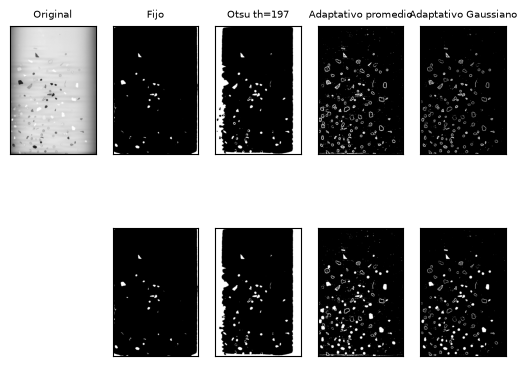

In [2]:
#Carga imagen directamente en grises
imgorig = cv2.imread('MPs_test.jpg', cv2.IMREAD_GRAYSCALE) 

img = cv2.GaussianBlur(imgorig,(5,5),0)

#Umbralizados
ret,imth1 = cv2.threshold(img,150,255,cv2.THRESH_BINARY_INV)
thotsu,imth2 = cv2.threshold(img,0,255,cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)
print('Umbral escogido ', thotsu)
imth3 = cv2.adaptiveThreshold(img,255,cv2.ADAPTIVE_THRESH_MEAN_C,\
            cv2.THRESH_BINARY,11,2)
imth4 = cv2.adaptiveThreshold(img,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,\
            cv2.THRESH_BINARY,11,2)
 
titles = ['Original', 'Fijo','Otsu th='+str(int(thotsu)),
            'Adaptativo promedio', 'Adaptativo Gaussiano']
images = [img, imth1, imth2, 255 - imth3, 255 - imth4]
 
for i in range(5):
    plt.subplot(2,5,i+1),plt.imshow(images[i],'gray')
    plt.title(titles[i], fontsize=7)
    plt.xticks([]),plt.yticks([])

    #Obtiene únicamente los contornos externos
    if i>0:
        res,imth = cv2.threshold(images[i],120,255,cv2.THRESH_BINARY)
        contornos, hierarchy= cv2.findContours(imth, 
        cv2.RETR_EXTERNAL , 
        cv2.CHAIN_APPROX_SIMPLE)  
        img_cont = np.zeros(img.shape)
        cv2.drawContours(img_cont, contornos, -1, (255,255,255), -1)  
        plt.subplot(2,5,i+6),plt.imshow(img_cont,'gray')
        plt.xticks([]),plt.yticks([])
plt.show()

Para esta imagen de muestras de microplásticos tenemos una anotación (que puede contener errores) de la tipología de las partículas. Esta será la imagen de test en los experimentos posteriores, no puedes hacer uso de esta imagen para entrenar tu clasificador, solo par evaluarlo

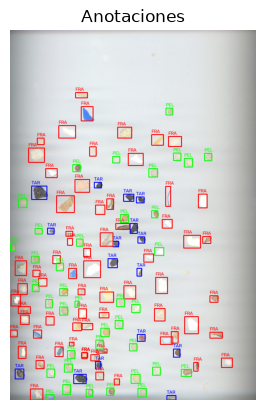

In [3]:
# Imagen y anotaciones
imagen = "MPs_test.jpg"          # Imagen original
csv_file = "MPs_test_bbs.csv"  # CSV con coordenadas y tipología

# Colores de cada clase
colores = {
    "FRA": (0, 0, 255),   # Rojo 
    "PEL": (0, 255, 0),   # Verde
    "TAR": (255, 0, 0)    # Azul
}

# Imagen
img = cv2.imread(imagen)

# Cara csv y dibujar rectángulos
with open(csv_file, newline="") as file:
    reader = csv.DictReader(file)
    for row in reader:
        etiqueta = row["label"]
        x_min, y_min, x_max, y_max = map(int, [row["x_min"], row["y_min"], row["x_max"], row["y_max"]])
        
        # Color según etiqueta
        color = colores.get(etiqueta, (0, 0, 0))  # negro por defecto si no encuentra
        
        # Dibujar rectángulo
        cv2.rectangle(img, (x_min, y_min), (x_max, y_max), color, 2)
        
        # Etiqueta 
        cv2.putText(img, etiqueta, (x_min, y_min - 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)

# Visualiza resultado
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Anotaciones")
plt.axis('off')
plt.show()


##Muestras de entrenamiento

Text(0.5, 1.0, 'Alquitrán')

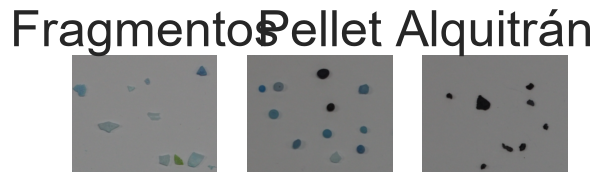

In [9]:
#Cargamos tres subimágenes, por simplicidad, de cada uno de los tres tipos considerados (reiterar que el alquitrán no es microplástico)
imgF = cv2.imread('./tarea2_img/fragment/FRA.png') 
imgP = cv2.imread('./tarea2_img/pellet/PEL.png') 
imgT = cv2.imread('./tarea2_img/alquitran/TAR.png') 

#Mostramos
plt.subplot(131)
plt.axis("off")
plt.imshow(imgF) 
plt.title('Fragmentos')
plt.subplot(132)
plt.axis("off")
plt.imshow(imgP) 
plt.title('Pellet')
plt.subplot(133)
plt.axis("off")
plt.imshow(imgT) 
plt.title('Alquitrán')

El objetivo de la siguiente tarea, descrita más abajo, es desarrollar tu propio clasificador basado únicamente en heurísticas basadas en características geométricas y/o de apariencia, a partir de las imágenes completas de las partículas de cada tipo, debiendo mostrar la bondad del clasificador haciendo uso de métricas para ello sobre las anotaciones de la imagen de test *MPs_test.png*. La siguiente celda obtiene varias métricas para un conjunto de datos imaginario (y con etiquetas aleatorias). Si bien las trataremos con más detalle en teoría, muestro un repertorio de ellas, dando más peso a la matriz de confusión. La ejecución de la celda requiere instalar el paquete scikit-learn.

¿Qué es una matriz de confusión?
Se utiliza para mostrar el comportamiento de un clasificador para las distintas clases conocidas, se relacionan las etiquetas de las muestras anotadas frente a las predichas por el clasificador. Se busca una matriz diagonal, pero la perfección es infrecuente.

El siguiente ejemplo, muestra el modo de obtener la matriz de confusión para un hipotético problema con cuatro clases, y valores de anotación (variable y) y predicción (variable y_pred) obtenidos de forma aleatoria.

Anotaciones  [3, 2, 1, 0, 1, 1, 0, 1, 3, 2, 2, 2, 0, 2, 3, 1, 2, 1, 2, 3, 2, 1, 1, 3, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 3, 1, 2, 3, 2, 0, 2, 3, 1, 1, 1, 3, 0, 0, 3, 1, 1, 3, 1, 0, 2, 2, 2, 3, 2, 2, 3, 0, 0, 2, 1, 3, 3, 2, 2, 2, 2, 2, 1, 0, 3, 0, 3, 3, 3, 3, 3, 0, 0, 1, 1, 3, 2, 1, 0, 0, 2, 2, 3, 2, 2, 2, 1, 1, 3, 2]
Predicciones  [2, 3, 2, 0, 0, 0, 3, 1, 3, 3, 3, 3, 3, 2, 2, 3, 1, 2, 0, 2, 2, 1, 0, 0, 1, 0, 3, 0, 1, 0, 3, 0, 0, 0, 1, 0, 2, 3, 0, 0, 1, 0, 2, 2, 2, 3, 1, 3, 1, 2, 2, 0, 3, 2, 3, 2, 3, 1, 0, 1, 2, 0, 3, 1, 1, 0, 3, 3, 3, 0, 3, 3, 0, 3, 2, 3, 3, 3, 1, 2, 2, 2, 3, 1, 2, 2, 3, 3, 2, 1, 1, 3, 1, 0, 3, 0, 0, 1, 2, 0]
¿Cómo de bien encajan anotación y predicción?
Accuracy (TP/(n))= 0.21
Precision (TP/(TP+FP)) = 0.21166753732967653
Recall (TP/(TP+FN)) = 0.21
F1 Score (2*(precision*recall)/(precision+recall)) = 0.20753202032367027


Text(38.236490885416664, 0.5, 'Real/Anotado')

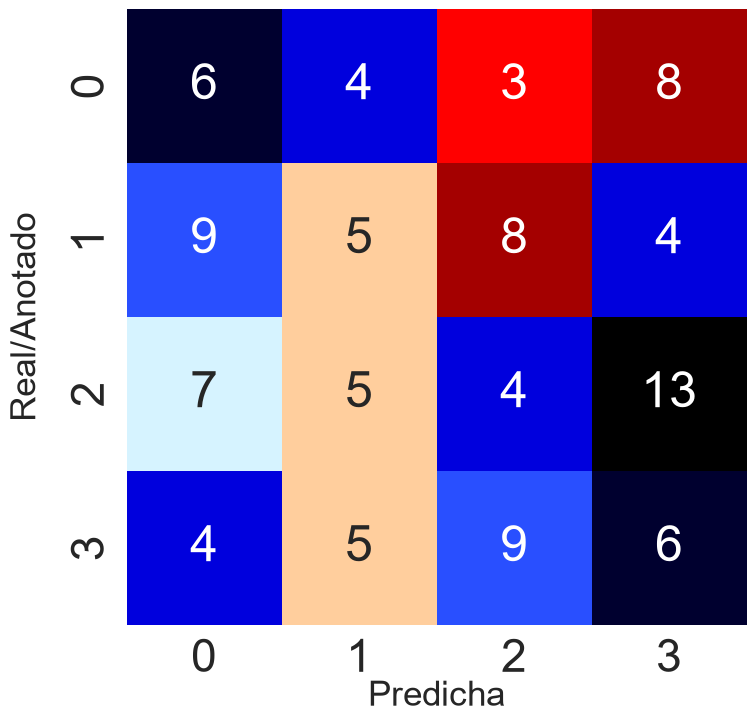

In [7]:

import random
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


# Numero de muestras
n = 100  
nclases = 4

# A falta de clasificador y conjunto de datos, creamos anotaciones y predicciones de forma aleatoria
# Vector aleatorio con etiquetas anotadas
y = [random.randint(0, nclases - 1) for _ in range(n)]
print('Anotaciones ' , y)

# Vector aleatorio con etiquetas predichas por un supuesto clasificador
y_pred = [random.randint(0, nclases - 1) for _ in range(n)]
print('Predicciones ' , y_pred)

print('¿Cómo de bien encajan anotación y predicción?')

#Cálculo de métricas
accuracy = accuracy_score(y, y_pred)
#Para más de una clase se define la forma de promediar
precision = precision_score(y, y_pred,average='weighted')
recall = recall_score(y, y_pred,average='weighted')
f1score = f1_score(y, y_pred,average='weighted')

print(f"Accuracy (TP/(n))= {accuracy}")
print(f"Precision (TP/(TP+FP)) = {precision}")
print(f"Recall (TP/(TP+FN)) = {recall}")
print(f"F1 Score (2*(precision*recall)/(precision+recall)) = {f1score}")


conf_matrix = confusion_matrix(y, y_pred)
plt.figure(figsize=(8,8))
sns.set(font_scale = 1.75)#tamaños tipografía
sns.set(font_scale = 3.0)

ax = sns.heatmap(
        conf_matrix, # confusion matrix 2D array 
        annot=True, # Muestra números en las celdas
        fmt='d', # valores enteros
        cbar=False, # sin barra de colores
        cmap='flag', # mapa de colores
        #vmax=175 # contraste de color
    )

#Etiquetas matriz de confusión
label_font = {'size':'25'}
ax.set_xlabel("Predicha", labelpad=-0.75, fontdict=label_font)
ax.set_ylabel("Real/Anotado", labelpad=20, fontdict=label_font)

TAREA: La tarea consiste en extraer características (geométricas y/o visuales) de las tres imágenes completas de partida, y *aprender* patrones que permitan identificar las partículas en nuevas imágenes. Para ello se proporciona como imagen de test *MPs_test.jpg* y sus correpondientes anotaciones *MPs_test_bbs.csv* con la que deben obtener las métricas para su propuesta de clasificación de microplásticos, además de la matriz de confusión. La matriz de confusión permitirá mostrar para cada clase el número de muestras que se clasifican correctamente de dicha clase, y el número de muestras que se clasifican incorrectamente como perteneciente a una de las otras dos clases. De nuevo, no deben hacer uso de modelos de aprendizaje `profunfop ni poara segmentar,  ni para clasificar.

En el trabajo [SMACC: A System for Microplastics Automatic Counting and Classification](https://doi.org/10.1109/ACCESS.2020.2970498), las características geométricas utilizadas fueron:

- Área en píxeles
- Perímetro en píxeles
- Compacidad (relación entre el cuadrado del perímetro y el área de la partícula)
- Relación del área de la partícula con la del contenedor
- Relación del ancho y el alto del contenedor
- Relación entre los ejes de la elipse ajustada
- Definido el centroide, relación entre las distancias menor y mayor al contorno

Si no se quedan satisfechos con la segmentación obtenida, es el mundo real, también en el README comento técnicas recientes de segmentación, que podrían despertar su curiosidad.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

## Solución tarea 2

In [85]:
"""
Segmentación (técnicas clásicas) y extracción de las 7 características
geométricas de SMACC para partículas de microplástico / alquitrán.
Uso en notebook:  from mp_features import *
"""
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FEATURE_NAMES = [
    "area", "perimetro", "compacidad", "area_ratio_bbox",
    "ratio_bbox_wh", "ratio_ejes_elipse", "ratio_dist_centroide",
]


# ----------------------------------------------------------------------
# 1. Carga
# ----------------------------------------------------------------------
def cargar(ruta):
    """Carga una imagen en RGB y falla con un mensaje claro si no existe."""
    if not os.path.exists(ruta):
        raise FileNotFoundError(f"No existe: {os.path.abspath(ruta)}")
    img = cv2.imread(ruta)
    if img is None:
        raise ValueError(f"OpenCV no pudo leer: {ruta}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


# ----------------------------------------------------------------------
# 2. Segmentación
# ----------------------------------------------------------------------
def segmentar(img_rgb, area_min=30, area_max=None, block_size=11, C=2, kernel=1):

    # adaptiveThreshold requiere una imagen de 8 bits y un solo canal.
    gris = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    gris = cv2.GaussianBlur(gris, (5, 5), 0)

    # Las partículas oscuras pasan a blanco; el fondo queda negro.
    mask = cv2.adaptiveThreshold(gris, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 
                                 cv2.THRESH_BINARY_INV, block_size, C)

    # Limpia ruido y pequeños huecos, si kernel es mayor que 1.
    if kernel > 1:
        ker = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (kernel, kernel)
        )
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, ker)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, ker)

    mask = rellenar_huecos(mask)

    # Elimina componentes conectados fuera del rango de área.
    n, labels, stats, _ = cv2.connectedComponentsWithStats(
        mask, connectivity=8
    )
    limpia = np.zeros_like(mask)

    for i in range(1, n):  # El componente 0 corresponde al fondo.
        area = stats[i, cv2.CC_STAT_AREA]
        if area >= area_min and (area_max is None or area <= area_max):
            limpia[labels == i] = 255

    return limpia


def rellenar_huecos(mask):
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    out = np.zeros_like(mask)
    cv2.drawContours(out, cnts, -1, 255, thickness=cv2.FILLED)
    return out


# ----------------------------------------------------------------------
# 3. Características geométricas (las 7 del artículo SMACC)
# ----------------------------------------------------------------------
def caracteristicas_contorno(cnt):
    """Calcula las 7 características de un contorno de OpenCV."""
    area = cv2.contourArea(cnt)
    perim = cv2.arcLength(cnt, True)
    if area == 0 or perim == 0 or len(cnt) < 5:      # fitEllipse necesita >= 5 puntos
        return None

    # 3) Compacidad
    compacidad = perim ** 2 / area

    # 4) y 5) Contenedor (bounding box alineada con ejes)
    x, y, w, h = cv2.boundingRect(cnt)
    area_ratio = area / (w * h)
    ratio_wh = w / h

    # 6) Elipse ajustada: cociente eje menor / eje mayor (en [0,1])
    (_, _), (d1, d2), _ = cv2.fitEllipse(cnt)
    ratio_elipse = min(d1, d2) / max(d1, d2)

    # 7) Distancias centroide-contorno: mínima / máxima
    M = cv2.moments(cnt)
    cx, cy = M["m10"] / M["m00"], M["m01"] / M["m00"]
    pts = cnt.reshape(-1, 2).astype(float)
    dist = np.hypot(pts[:, 0] - cx, pts[:, 1] - cy)
    ratio_dist = dist.min() / dist.max()

    return [area, perim, compacidad, area_ratio, ratio_wh,
            ratio_elipse, ratio_dist], (x, y, w, h)


def extraer_particulas(mask):
    """
    Dada una máscara binaria devuelve:
      df   -> DataFrame con las características (una fila por partícula)
      cnts -> lista de contornos (mismo orden que df)
      bbs  -> lista de cajas (x, y, w, h)
    """
    contornos, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL,
                                    cv2.CHAIN_APPROX_NONE)
    filas, cnts, bbs = [], [], []
    for c in contornos:
        r = caracteristicas_contorno(c)
        if r is None:
            continue
        feats, bb = r
        filas.append(feats)
        cnts.append(c)
        bbs.append(bb)
    return pd.DataFrame(filas, columns=FEATURE_NAMES), cnts, bbs


# ----------------------------------------------------------------------
# 4. Construcción del conjunto de entrenamiento
# ----------------------------------------------------------------------
def dataset_entrenamiento(rutas_por_clase, **kwargs_seg):
    """
    rutas_por_clase: dict {'fragmento': [rutas...], 'pellet': [...], 'alquitran': [...]}
    Cada imagen contiene partículas de UNA sola clase, así que todas las
    partículas segmentadas reciben esa etiqueta.
    """
    dfs = []
    for clase, rutas in rutas_por_clase.items():
        for r in rutas:
            img = cargar(r)
            mask = segmentar(img, **kwargs_seg)
            df, _, _ = extraer_particulas(mask)
            df["clase"] = clase
            df["imagen"] = os.path.basename(r)
            dfs.append(df)
    return pd.concat(dfs, ignore_index=True)


# ----------------------------------------------------------------------
# 5. Visualización
# ----------------------------------------------------------------------
def mostrar_segmentacion(img_rgb, mask, cnts=None, bbs=None, titulo=""):
    vis = img_rgb.copy()
    if cnts is None:
        cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(vis, cnts, -1, (0, 255, 0), 2)
    if bbs is not None:
        for i, (x, y, w, h) in enumerate(bbs):
            cv2.rectangle(vis, (x, y), (x + w, y + h), (255, 0, 0), 2)
            cv2.putText(vis, str(i), (x, y - 5), cv2.FONT_HERSHEY_SIMPLEX,
                        0.8, (255, 0, 0), 2)
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    ax[0].imshow(img_rgb); ax[0].set_title("Original")
    ax[1].imshow(mask, cmap="gray"); ax[1].set_title("Máscara")
    ax[2].imshow(vis); ax[2].set_title("Contornos" + (" " + titulo if titulo else ""))
    for a in ax:
        a.axis("off")
    plt.tight_layout()
    plt.show()

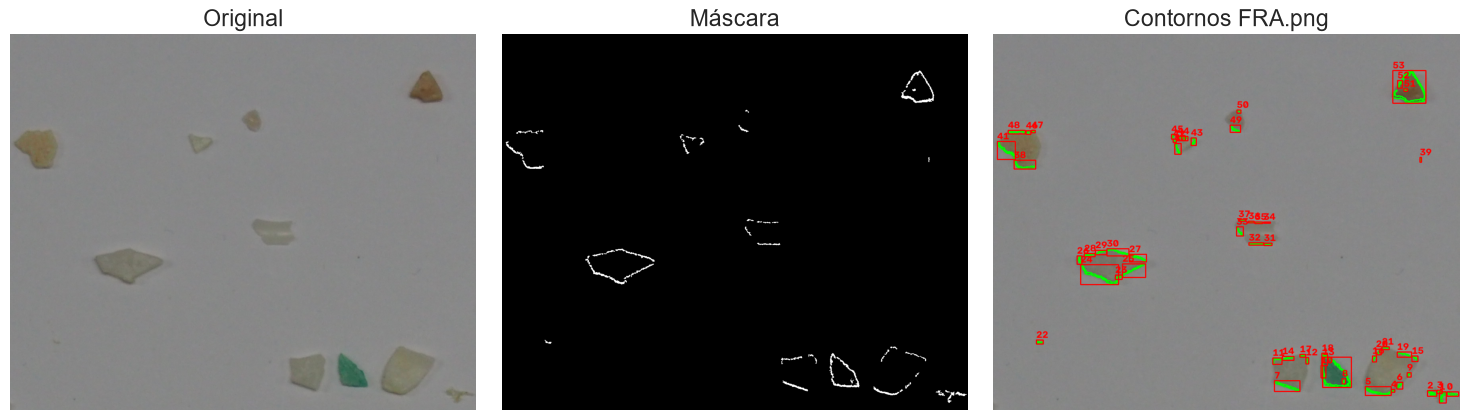

54 partículas


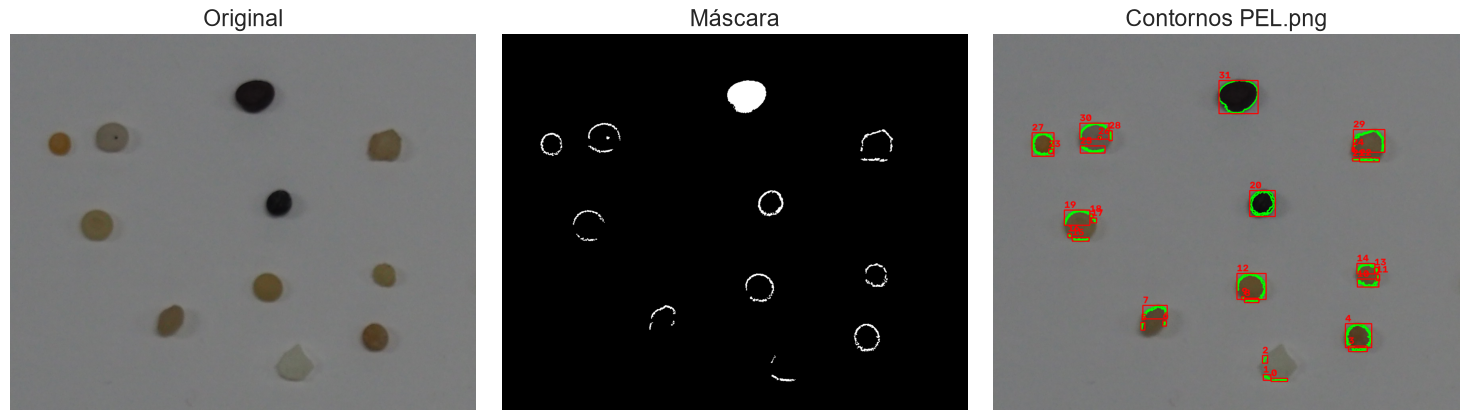

32 partículas


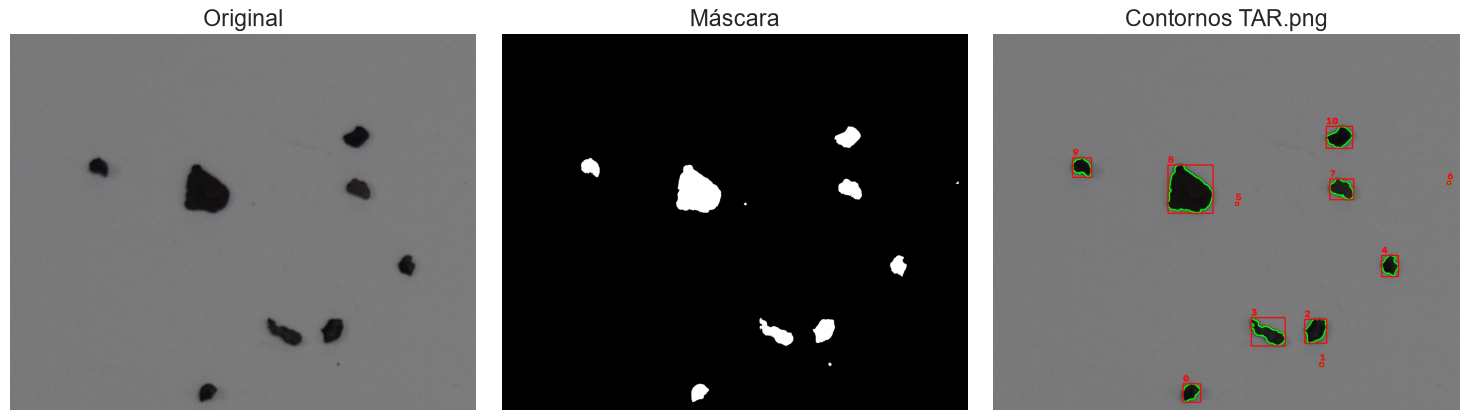

11 partículas
clase
FRA    290
PEL    211
TAR     92
dtype: int64
           area  perimetro  compacidad  area_ratio_bbox  ratio_bbox_wh  \
clase                                                                    
FRA     204.507    116.285     102.363            0.260          2.165   
PEL     251.502    153.093     140.054            0.263          3.177   
TAR    1240.217    199.614      94.720            0.498          4.494   

       ratio_ejes_elipse  ratio_dist_centroide  
clase                                           
FRA                0.424                 0.127  
PEL                0.515                 0.176  
TAR                0.584                 0.375  
Accuracy CV: 0.631


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",0
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1

In [86]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

# 1) Comprobar la segmentación en cada imagen de entrenamiento
for ruta in ['./tarea2_img/fragment/FRA.png',
             './tarea2_img/pellet/PEL.png',
             './tarea2_img/alquitran/TAR.png']:
    img = cargar(ruta)
    mask = segmentar(img)                      # prueba metodo='sauvola' también
    df, cnts, bbs = extraer_particulas(mask)
    mostrar_segmentacion(img, mask, cnts, bbs, titulo=os.path.basename(ruta))
    print(len(df), "partículas")

# 2) Construir el dataset de entrenamiento (una etiqueta por imagen)
rutas = {
    'FRA': ['./tarea2_img/fragment/fragment-03-olympus-10-01-2020.JPG'],
    'PEL':    ['./tarea2_img/pellet/pellet-03-olympus-10-01-2020.JPG'],
    'TAR': ['./tarea2_img/alquitran/tar-03-olympus-10-01-2020.JPG'],
}
train = dataset_entrenamiento(rutas)
print(train.groupby('clase').size())
print(train.groupby('clase')[FEATURE_NAMES].mean().round(3))

X, y = train[FEATURE_NAMES], train["clase"]
clf = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=0)

# Validación cruzada (usa como máximo tantos folds como muestras tenga la clase más pequeña)
n_min = y.value_counts().min()
cv = StratifiedKFold(n_splits=min(5, n_min), shuffle=True, random_state=0)
print("Accuracy CV:", cross_val_score(clf, X, y, cv=cv).mean().round(3))

clf.fit(X, y)   # entrenamiento final con todos los datos

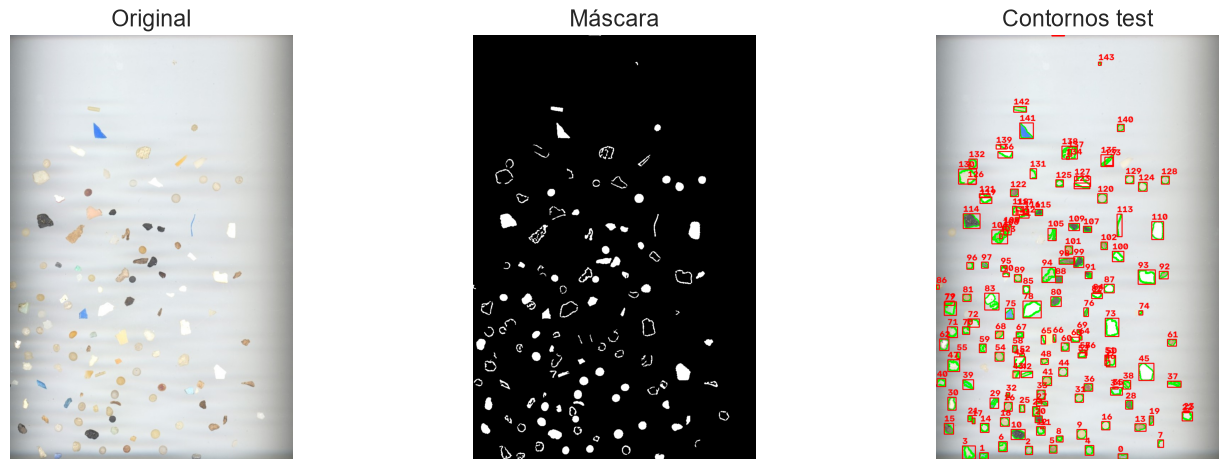

145 partículas detectadas
  label  x_min  y_min  x_max  y_max
0   TAR    503   1171    532   1186
1   TAR    204   1103    244   1133
2   TAR     16   1086     44   1118
3   TAR    524   1022    545   1048
4   TAR    408    975    433    997
label
FRA    66
PEL    38
TAR    16
Name: count, dtype: int64


In [87]:
RUTA_TEST = './MPs_test.jpg'      # ajusta las rutas
RUTA_CSV  = './MPs_test_bbs.csv'

img_test = cargar(RUTA_TEST)
mask_test = segmentar(img_test)    # usa los mismos parámetros que en train
df_test, cnts_test, bbs_test = extraer_particulas(mask_test)
mostrar_segmentacion(img_test, mask_test, cnts_test, bbs_test, titulo="test")

df_test["pred"] = clf.predict(df_test[FEATURE_NAMES])
print(len(df_test), "partículas detectadas")

ann = pd.read_csv(RUTA_CSV)
print(ann.head())
print(ann['label'].value_counts())     # comprueba qué etiquetas hay realmente

# Traducción de las etiquetas del CSV a las clases del entrenamiento
MAPEO = {'TAR': 'alquitran', 'FRA': 'fragmento', 'PEL': 'pellet'}   # verifica FRA y PEL con value_counts()

ann_xyxy  = ann[['x_min', 'y_min', 'x_max', 'y_max']].to_numpy(dtype=float)
ann_clase = ann['label'].map(MAPEO).to_numpy()

# Si alguna etiqueta no estaba en MAPEO saldrá NaN: avisamos
assert not pd.isna(ann_clase).any(), f"Etiquetas sin mapear: {set(ann['label']) - set(MAPEO)}"

Etiquetas en las anotaciones: ['FRA', 'PEL', 'TAR']
Clases del clasificador: ['FRA' 'PEL' 'TAR']
{'TAR', 'FRA', 'PEL'} {'TAR', 'FRA', 'PEL'}
Anotaciones: 120 | Detecciones: 145 | Emparejadas: 93
Anotaciones sin detectar: 27
Detecciones sin anotación (falsos positivos de segmentación): 52


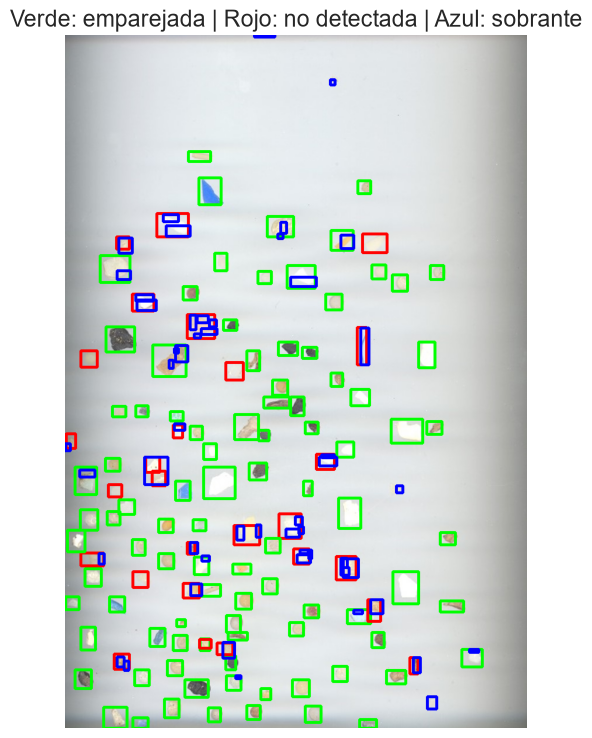

In [88]:
from scipy.optimize import linear_sum_assignment

def iou_matriz(a, b):
    """IoU entre cajas a (N,4) y b (M,4), ambas en formato xyxy."""
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0])
    iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2])
    iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter)

# Comprobación: las clases del CSV deben ser las que conoce el clasificador
clases = list(clf.classes_)
desconocidas = set(ann_clase) - set(clases)

# Cajas detectadas (x, y, w, h) -> xyxy
det_xyxy = np.array([[x, y, x + w, y + h] for (x, y, w, h) in bbs_test], dtype=float)

IOU_MIN = 0.5
iou = iou_matriz(ann_xyxy, det_xyxy)                  # filas: anotaciones, columnas: detecciones
filas, cols = linear_sum_assignment(-iou)             # asignación 1 a 1 que maximiza IoU
pares = [(i, j) for i, j in zip(filas, cols) if iou[i, j] >= IOU_MIN]

MAPEO = {0: 'FRA', 1: 'PEL', 2: 'TAR'}   # AJUSTA según lo que veas arriba

ann_clase = (
    ann["label"]
    .astype(str)
    .str.strip()
    .str.upper()
    .to_numpy()
)
assert not pd.isna(ann_clase).any(), "Hay números sin mapear"

print("Etiquetas en las anotaciones:", sorted(set(ann_clase)))
print("Clases del clasificador:", clf.classes_)

desconocidas = set(ann_clase) - set(clf.classes_)
if desconocidas:
    raise ValueError(f"Etiquetas sin clase correspondiente en el clasificador: {desconocidas}")

y = [ann_clase[i] for i, j in pares]
clases = list(clf.classes_)

y      = [ann_clase[i] for i, j in pares]             # etiqueta real (CSV)
y_pred = [df_test["pred"].iloc[j] for i, j in pares]  # etiqueta predicha

print(set(y), set(y_pred))               # ambos deben ser subconjuntos de FRA, PEL, TAR

n_ann, n_det, n_match = len(ann_xyxy), len(det_xyxy), len(pares)
print(f"Anotaciones: {n_ann} | Detecciones: {n_det} | Emparejadas: {n_match}")
print(f"Anotaciones sin detectar: {n_ann - n_match}")
print(f"Detecciones sin anotación (falsos positivos de segmentación): {n_det - n_match}")

# Visualización: verde = emparejada, rojo = anotación sin detectar, azul = detección sin anotación
ann_ok = {i for i, _ in pares}
det_ok = {j for _, j in pares}
vis = img_test.copy()
for i, (x1, y1, x2, y2) in enumerate(ann_xyxy.astype(int)):
    color = (0, 255, 0) if i in ann_ok else (255, 0, 0)
    cv2.rectangle(vis, (x1, y1), (x2, y2), color, 3)
for j, (x1, y1, x2, y2) in enumerate(det_xyxy.astype(int)):
    if j not in det_ok:
        cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 0, 255), 3)
plt.figure(figsize=(12, 9)); plt.imshow(vis); plt.axis("off")
plt.title("Verde: emparejada | Rojo: no detectada | Azul: sobrante"); plt.show()

Accuracy  = 0.538
Precision = 0.548
Recall    = 0.538
F1 Score  = 0.539

              precision    recall  f1-score   support

         FRA       0.59      0.52      0.55        44
         PEL       0.55      0.52      0.53        33
         TAR       0.43      0.62      0.51        16

    accuracy                           0.54        93
   macro avg       0.52      0.55      0.53        93
weighted avg       0.55      0.54      0.54        93



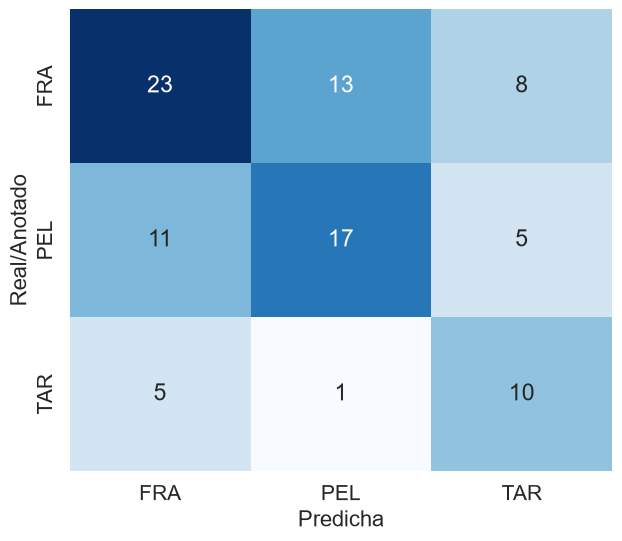

In [89]:
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report)
import seaborn as sns

accuracy  = accuracy_score(y, y_pred)
precision = precision_score(y, y_pred, average='weighted', labels=clases, zero_division=0)
recall    = recall_score(y, y_pred, average='weighted', labels=clases, zero_division=0)
f1score   = f1_score(y, y_pred, average='weighted', labels=clases, zero_division=0)

print(f"Accuracy  = {accuracy:.3f}")
print(f"Precision = {precision:.3f}")
print(f"Recall    = {recall:.3f}")
print(f"F1 Score  = {f1score:.3f}\n")
print(classification_report(y, y_pred, labels=clases, zero_division=0))

conf_matrix = confusion_matrix(y, y_pred, labels=clases)
plt.figure(figsize=(7, 6))
sns.set(font_scale=1.4)
ax = sns.heatmap(conf_matrix, annot=True, fmt='d', cbar=False, cmap='Blues',
                 xticklabels=clases, yticklabels=clases)
ax.set_xlabel("Predicha", fontsize=16)
ax.set_ylabel("Real/Anotado", fontsize=16)
plt.show()